# Assignment 2 — Supervised Learning with SVM

## Group Members
- Mohammad Ruhan Zahif Akhter Ghantiwala
- Aurelija Putnaite
- Subhanjan Shah


In [3]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
df = pd.read_csv("viral_songs_structured.csv")

df.head()

,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,Artist_1519,Pop,2013,237,0.052778,0.488194,0.518750,140.08.00,0.079861,0.071528,0.143056,0.188889,-9.41,661412,1
1,Artist_0458,Electronic,2018,239,0.302778,0.648611,0.466667,105.01.00,0.016000,0.002000,0.024000,0.000000,-9.89,1114175,1
2,Artist_1386,Hip-Hop,2014,148,0.445833,0.503472,0.460000,90.06.00,0.010000,0.520000,0.079000,0.053000,-5.53,105832,1
3,Artist_0865,Classical,2012,216,0.226389,0.316667,0.207639,71.03.00,0.670833,0.042000,0.000000,0.074000,-11.39,915397,0
4,Artist_0192,Pop,2011,277,0.415972,0.474306,0.070000,132.06.00,0.078000,0.078472,0.000000,0.036000,-5.56,3690733,1


## Ruhan's Part — Dataset Explanation, Initial SVM Models, and Applications

### Task 1A — Dataset, preparation, and initial SVM models


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score

## Task 1B — Decision-Boundary Visualizations
### Subhanjan Shah

I compare the decision boundaries of linear and polynomial SVM
models using song duration and loudness as the two input features.

In [6]:
X_visual = df[['duration_sec', 'loudness_db']]
y_visual = df['viral']

print(X_visual.head())
print(y_visual.head())

   duration_sec  loudness_db
0           237        -9.41
1           239        -9.89
2           148        -5.53
3           216       -11.39
4           277        -5.56
0    1
1    1
2    1
3    0
4    1
Name: viral, dtype: int64


In [7]:
X_visual_train, X_visual_test, y_visual_train, y_visual_test = (
    train_test_split(
        X_visual,
        y_visual,
        test_size=0.2,
        random_state=42,
        stratify=y_visual
    )
)

print("Training shape:", X_visual_train.shape)
print("Testing shape:", X_visual_test.shape)

Training shape: (8000, 2)
Testing shape: (2000, 2)


In [8]:
linear_visual = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1)
)

polynomial_visual = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="poly",
        degree=3,
        C=1,
        coef0=1,
        gamma="scale"
    )
)

visual_models = {
    "Linear SVM": linear_visual,
    "Polynomial SVM": polynomial_visual
}

visual_accuracies = {}

for name, model in visual_models.items():
    model.fit(X_visual_train, y_visual_train)

    predictions = model.predict(X_visual_test)

    accuracy = accuracy_score(y_visual_test, predictions)
    visual_accuracies[name] = accuracy

    print(f"{name} — test accuracy: {accuracy:.2%}")

Linear SVM — test accuracy: 63.95%
Polynomial SVM — test accuracy: 63.95%


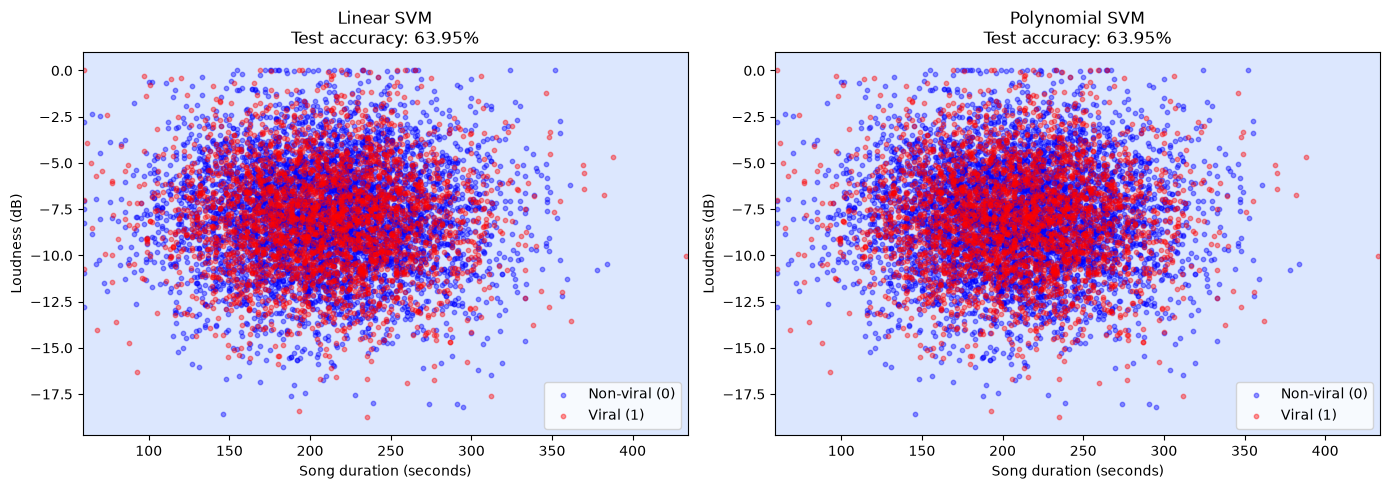

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, visual_models.items()):

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_visual_train,
        response_method="predict",
        cmap="coolwarm",
        alpha=0.3,
        ax=ax
    )

    for label, color, class_name in [
        (0, "blue", "Non-viral (0)"),
        (1, "red", "Viral (1)")
    ]:
        class_rows = y_visual_train == label

        ax.scatter(
            X_visual_train.loc[class_rows, 'duration_sec'],
            X_visual_train.loc[class_rows, 'loudness_db'],
            color=color,
            label=class_name,
            s=10,
            alpha=0.4
        )

    ax.set_xlabel("Song duration (seconds)")
    ax.set_ylabel("Loudness (dB)")
    ax.set_title(
        f"{name}\n"
        f"Test accuracy: {visual_accuracies[name]:.2%}"
    )
    ax.legend()

plt.tight_layout()
plt.show()

### Task 2 — Two Real-World SVM Applications - RUHAN

## Aurelija's Part — Parameter Tuning and Kernel Comparison

### Task 3 — Effects of Changing C

### Task 4 — Linear versus Polynomial Kernel Performance